# Baseline versie Mattijn / M.b.v. Stijn

Gemaakt door Mattijn
Studentnummer: 587915

Geholpen door Stijn
Studentnummer: 583205
____
In dit Jupiter Notebook word een basis baseline model gemaakt op basis van de imputed data uit het bestand [Base_Impute.ipynb](../Base_Impute.ipynb)

#### Uitgevoerde taken zijn:
* Augmented Dickey-Fuller Test
* Autocorrelatiefunctie
* ARIMA (p,d,q)
* SARIMA (p,d,q)(P,D,Q)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import itertools, time
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

#Projectmap zoeken, werkt vanuit elke submap van models/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
DATA_DIR = ROOT / "models" / "baseline" / "basic_impute_data.gzip"
RESULTS_DIR = ROOT / "models" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

runtimes = {}

In [2]:
df = pd.read_parquet(DATA_DIR)
df

,CO2,CTYPE,ENAME,ENE,EONNAME,ETYPE,GNAME,POW,source_zip,source_csv,...,CO2_EXP,COST,COST_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-09-30 22:05:00+00:00,9.143889,electricity,totaalverbruik-16eda211b788,83.888889,eiot-16eda211b788,powermeter,SERENE,1082.857143,240930_totaalverbruik-16eda211b788_89d7dccfc01...,240930_totaalverbruik-16eda211b788_89d7dccfc01...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09-30 22:10:00+00:00,9.835952,electricity,totaalverbruik-16eda211b788,90.238095,eiot-16eda211b788,powermeter,SERENE,1075.000000,240930_totaalverbruik-16eda211b788_89d7dccfc01...,240930_totaalverbruik-16eda211b788_89d7dccfc01...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09-30 22:15:00+00:00,9.764583,electricity,totaalverbruik-16eda211b788,89.583333,eiot-16eda211b788,powermeter,SERENE,1045.000000,240930_totaalverbruik-16eda211b788_89d7dccfc01...,240930_totaalverbruik-16eda211b788_89d7dccfc01...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09-30 22:20:00+00:00,29.172917,electricity,totaalverbruik-16eda211b788,87.083333,eiot-16eda211b788,powermeter,SERENE,1045.000000,240930_totaalverbruik-16eda211b788_89d7dccfc01...,240930_totaalverbruik-16eda211b788_89d7dccfc01...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09-30 22:25:00+00:00,29.172917,electricity,totaalverbruik-16eda211b788,87.083333,eiot-16eda211b788,powermeter,SERENE,1000.000000,240930_totaalverbruik-16eda211b788_89d7dccfc01...,240930_totaalverbruik-16eda211b788_89d7dccfc01...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31 22:35:00+00:00,2.221667,electricity,totaalverbruik-16eda211b788,17.916667,NaN,powermeter,NaN,215.000000,241231_totaalverbruik-16eda211b788_05fe092abcf...,241231_totaalverbruik-16eda211b788_05fe092abcf...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-12-31 22:40:00+00:00,2.221667,electricity,totaalverbruik-16eda211b788,17.916667,NaN,powermeter,NaN,185.000000,241231_totaalverbruik-16eda211b788_05fe092abcf...,241231_totaalverbruik-16eda211b788_05fe092abcf...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-12-31 22:45:00+00:00,1.911667,electricity,totaalverbruik-16eda211b788,15.416667,NaN,powermeter,NaN,185.000000,241231_totaalverbruik-16eda211b788_05fe092abcf...,241231_totaalverbruik-16eda211b788_05fe092abcf...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Augmented Dickey-Fuller Test (ADF)

In [3]:
# Alle Credits voor de Augmented Dickey-Fuller Test naar Stijn.
ADF= adfuller(df['POW'], result_object= True)
print(f'statistics= {ADF.statistic}')
print(f'p-value= {ADF.pvalue}')

statistics= -19.104563093059184
p-value= 0.0


**Conclussie:**
H0 verwerpen aangezien de P waarde kleiner is dan 0.05. de data hoeft niet gedifferentiërt te worden. 

____
### Autocorrelatiefunctie (ACF)

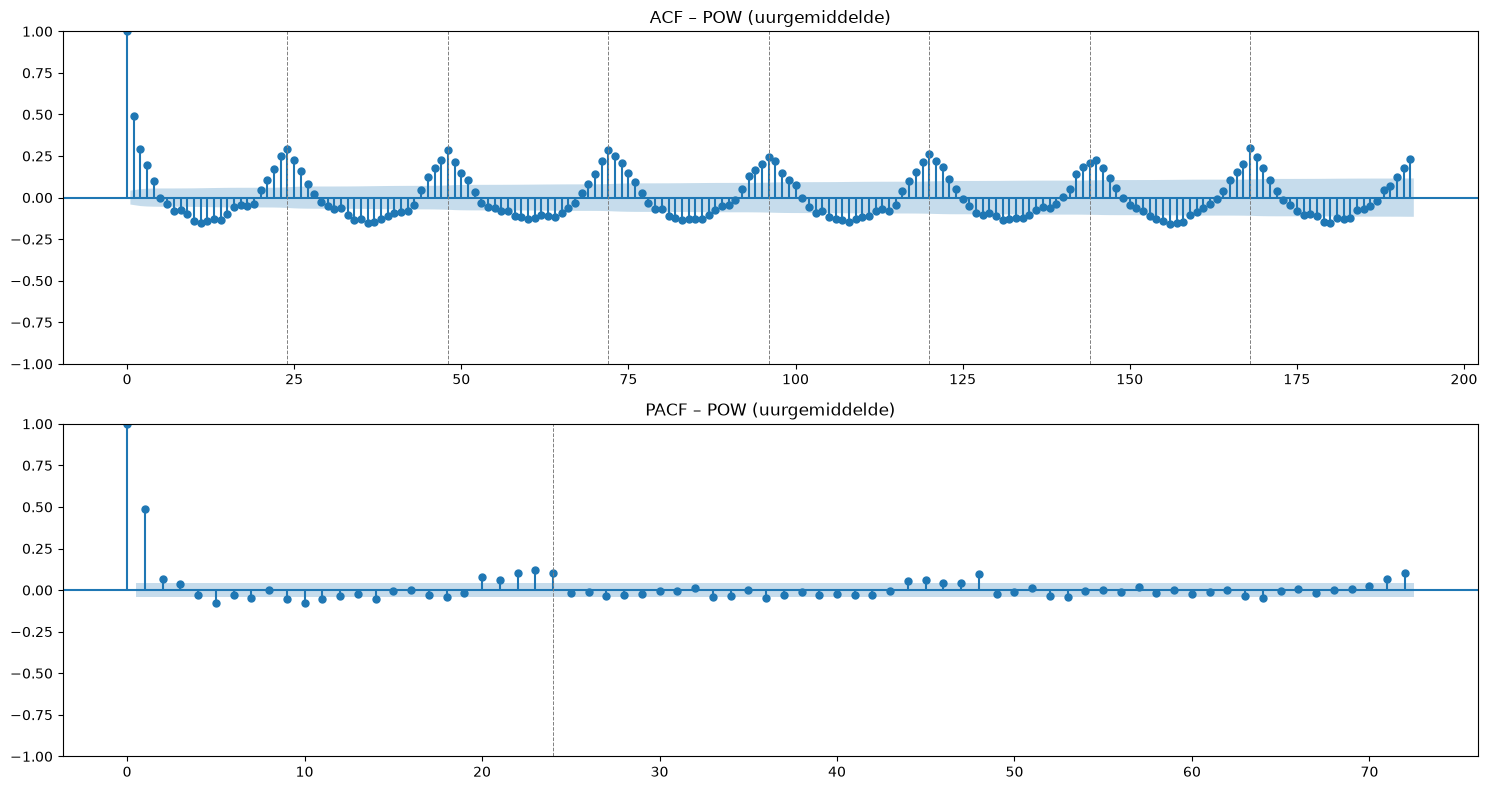

In [4]:
pow_uur = df['POW'].resample('h').mean()
# Reeks op uurbasis: 1 dag = 24 stappen, 1 week = 168 stappen

fig, axes = plt.subplots(2, 1, figsize=(15, 8))

plot_acf(pow_uur, lags=24 * 8, ax=axes[0])      # 8 dagen aan lagen
axes[0].set_title('ACF – POW (uurgemiddelde)')
for d in range(1, 8):
    axes[0].axvline(24 * d, color='grey', linestyle='--', linewidth=0.7)

plot_pacf(pow_uur, lags=24 * 3, ax=axes[1], method='ywm')
axes[1].set_title('PACF – POW (uurgemiddelde)')
axes[1].axvline(24, color='grey', linestyle='--', linewidth=0.7)

plt.tight_layout()
plt.show()


### Uitleg ACF- en PACF-plots

* **Blauwe band** = betrouwbaarheidsinterval (95%). Alles wat erbuiten steekt is statistisch significant. Met ±2.200 uurpunten is die band erg smal, dus bijna alles is "significant" (belangrijk) 
* **ACF piekt op lag 24, 48, 72, …** → dagelijkse seizoensinvloed. Dit bevestigt dat een `SARIMA met m = 24` nodig is, ook al gaf de ADF-test "stationair". Omdat er een bult zit rond stip 168, is er sprake van een weekpatroon. Dit kan een SARIMA met 1 seizoen niet meenemen.
* **PACF die na lag *p* abrupt afkapt** → suggestie voor **p** in ARIMA(p,d,q). Bij verbruiksdata zijn lag 1 en 2 vaak hoog en daarna klein: dan p = 1 of 2.
* **ACF die na lag *q* abrupt afkapt** → suggestie voor **q**. volgens internet komt bij dit soort data het AR-patroon vaker voor. Bron: [StackExchange](https://stats.stackexchange.com/questions/281666/how-does-acf-pacf-identify-the-order-of-ma-and-ar-terms)
* **Piek in de PACF rond lag 24** → seizoens-AR-term, dus `P = 1` in het (P,D,Q)-deel.
____

### Train-Test (≈11 weken om te trainen, 2 weken aan test)

In [5]:
pow_uur = df['POW'].resample('h').mean()

TEST_UREN = 24 * 14                      # laatste 2 weken als test
train = pow_uur.iloc[:-TEST_UREN]
test  = pow_uur.iloc[-TEST_UREN:]

print(f"train: van {train.index.min()} tot {train.index.max()}  ({len(train)} uur)")
print(f"test: van {test.index.min()} tot {test.index.max()}  ({len(test)} uur)")

train: van 2024-09-30 22:00:00+00:00 tot 2024-12-17 22:00:00+00:00  (1873 uur)
test: van 2024-12-17 23:00:00+00:00 tot 2024-12-31 22:00:00+00:00  (336 uur)


____
### ARIMA-model

Dit model gaat niet goed presteren maar is wel handig om te kijken of de *p, d, q* goed ingevuld worden voor de SARIMA en is hierdoor goed te onderbouwen
#### Grid search op AIC

In [6]:
#Grid wordt opgeslagen, zodat hij niet elke keer opnieuw hoeft
ARIMA_GRID_FILE = ROOT / "models" / "baseline" / "arima_grid.csv"
OPNIEUW_ZOEKEN_ARIMA = False        #True = grid search opnieuw draaien

if ARIMA_GRID_FILE.exists() and not OPNIEUW_ZOEKEN_ARIMA:
    grid = pd.read_csv(ARIMA_GRID_FILE)
    print("ARIMA-grid ingeladen uit", ARIMA_GRID_FILE.name)
else:
    resultaten = []
    for p, q in itertools.product(range(0, 5), range(0, 5)):
        try:
            model = ARIMA(train, order=(p, 0, q)).fit()
            resultaten.append({'p': p, 'd': 0, 'q': q, 'AIC': model.aic, 'BIC': model.bic})
            print(f"ARIMA({p},0,{q})  AIC={model.aic:.1f}")
        except Exception as e:
            print(f"ARIMA({p},0,{q}) mislukt: {e}")

    grid = pd.DataFrame(resultaten).sort_values('AIC').reset_index(drop=True)
    grid.to_csv(ARIMA_GRID_FILE, index=False)

grid.head(10)

ARIMA-grid ingeladen uit arima_grid.csv


,p,d,q,AIC,BIC
0,3,0,3,28266.670812,28310.953185
1,2,0,3,28292.507701,28331.254778
2,3,0,4,28301.505710,28351.323380
3,4,0,4,28351.502881,28406.855848
4,4,0,1,28351.835007,28390.582084
5,4,0,2,28352.227174,28396.509547
6,2,0,2,28357.985928,28391.197708
7,0,0,4,28368.946482,28402.158262
8,1,0,4,28369.174049,28407.921125
9,2,0,4,28369.946148,28414.228522


In [7]:
p, q = int(grid.loc[0, 'p']), int(grid.loc[0, 'q'])
t0 = time.perf_counter()
arima_best = ARIMA(train, order=(p, 0, q)).fit()
runtimes['training ARIMA'] = time.perf_counter() - t0
print(arima_best.summary())

# Voorspelling op de testperiode
pred = arima_best.forecast(steps=len(test))

print(f"MAE:  {mean_absolute_error(test, pred):.1f}")
print(f"RMSE: {root_mean_squared_error(test, pred):.1f}")

                               SARIMAX Results                                
Dep. Variable:                    POW   No. Observations:                 1873
Model:                 ARIMA(3, 0, 3)   Log Likelihood              -14125.335
Date:                Mon, 19 Oct 2026   AIC                          28266.671
Time:                        12:29:07   BIC                          28310.953
Sample:                    09-30-2024   HQIC                         28282.984
                         - 12-17-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        538.5372     23.623     22.797      0.000     492.237     584.837
ar.L1          2.3646      0.051     46.705      0.000       2.265       2.464
ar.L2         -1.8365      0.098    -18.771      0.0

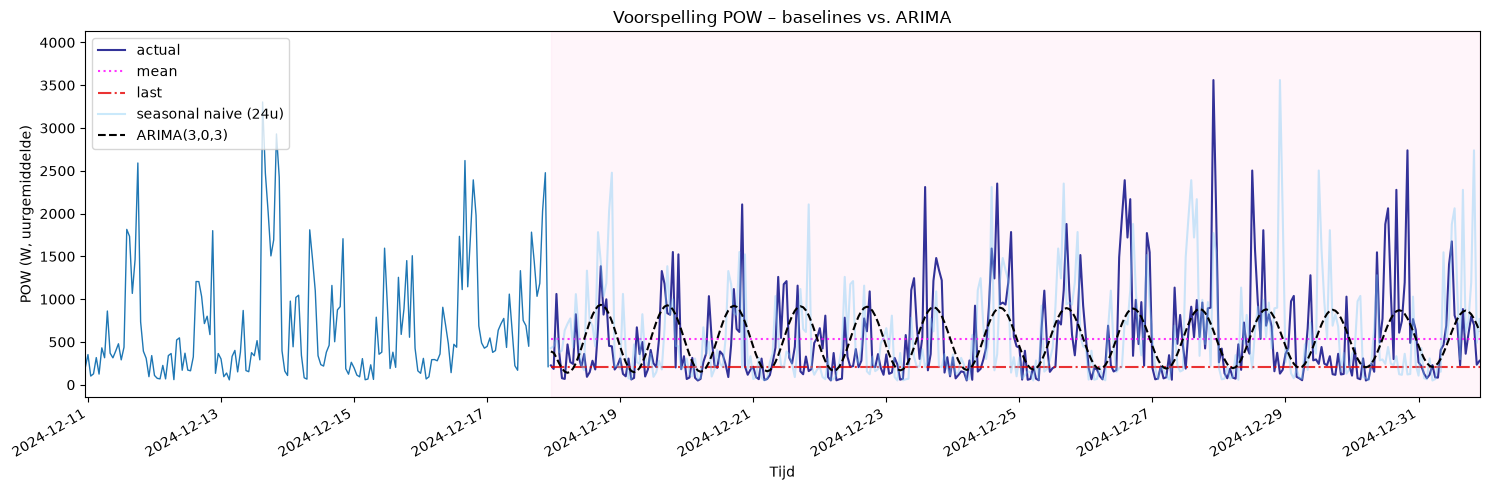

In [8]:
# --- Baselines op de testperiode ---
test_df = test.to_frame(name='actual')

test_df['pred_mean'] = train.mean()                        # gemiddelde van train (uit het boek van ML)
test_df['pred_last'] = train.iloc[-1]                      # laatste trainwaarde
test_df['pred_seasonal'] = pd.concat([train.iloc[-24:], test]).shift(24).loc[test.index]    # zelfde uur, dag ervoor (seasonal)
t0 = time.perf_counter()
test_df['pred_arima'] = arima_best.forecast(steps=len(test)).values
runtimes['voorspellen ARIMA'] = time.perf_counter() - t0


fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(train, color='tab:Blue', linewidth=1)
ax.plot(test_df['actual'],        color='#000080',  linestyle='-',   label='actual',                alpha=0.8)
ax.plot(test_df['pred_mean'],     color='#FF00FF',  linestyle=':',   label='mean',                  alpha=0.8)
ax.plot(test_df['pred_last'],     color='#E50000',  linestyle='-.',  label='last',                  alpha=0.8)
ax.plot(test_df['pred_seasonal'], color='#7Bc8F6',  linestyle='-',   label='seasonal naive (24u)',  alpha=0.4)
ax.plot(test_df['pred_arima'],    color='#000000',  linestyle='--',  label=f'ARIMA({p},0,{q})')
#Kleuren en opmaaak van deze plot is gedaan met behulp van https://matplotlib.org/stable/users/explain/colors/

ax.axvspan(test.index[0], test.index[-1], color="#FFCDEA", alpha=0.2)
ax.set_xlim(test.index[0] - pd.Timedelta(days=7), test.index[-1])  # 1 week train + test

ax.legend(loc=2)
ax.set_xlabel('Tijd')
ax.set_ylabel('POW (W, uurgemiddelde)')
ax.set_title('Voorspelling POW – baselines vs. ARIMA')

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

____
### SARIMA-model
de grid-search duurt maar een kleine 302 minuten om te draaien

In [9]:
m = 24              # Stukje terug bepaald door 24 uurs seizoeneneffect

#Grid search duurt ~5 uur, daarom wordt het resultaat opgeslagen en daarna ingeladen
SARIMA_GRID_FILE = ROOT / "models" / "baseline" / "sarima_grid.csv"
OPNIEUW_ZOEKEN_SARIMA = False       #True = grid search opnieuw draaien

if SARIMA_GRID_FILE.exists() and not OPNIEUW_ZOEKEN_SARIMA:
    grid_s = pd.read_csv(SARIMA_GRID_FILE)
    print("SARIMA-grid ingeladen uit", SARIMA_GRID_FILE.name)
else:
    resultaten = []
    for p, q, P, Q in itertools.product(range(0, 4), range(0, 4), range(0, 4), range(0, 4)):
        t0 = time.time() # Toegevoegd omdat ik begon te twijfelen dat hij wel iets deed (tijd werdt bijna exponentieel)
        try:
            model = SARIMAX(train,
                            order=(p, 0, q),
                            seasonal_order=(P, 1, Q, m),
                            enforce_stationarity=False,
                            enforce_invertibility=False).fit(disp=False)
            resultaten.append({'p': p, 'q': q, 'P': P, 'Q': Q,
                               'AIC': model.aic, 'BIC': model.bic})
            print(f"SARIMA({p},0,{q})({P},1,{Q},{m})  AIC={model.aic:.1f}  [{time.time()-t0:.0f}s]")
        except Exception as e:
            print(f"SARIMA({p},0,{q})({P},1,{Q},{m}) mislukt: {e}")

    grid_s = pd.DataFrame(resultaten).sort_values('AIC').reset_index(drop=True)
    grid_s.to_csv(SARIMA_GRID_FILE, index=False)

grid_s.head(10)

SARIMA-grid ingeladen uit sarima_grid.csv


,p,q,P,Q,AIC,BIC
0,0,3,1,3,26633.094238,26676.937664
1,3,0,3,3,26634.704565,26689.514486
2,0,3,0,3,26636.839657,26675.202656
3,3,0,3,2,26638.125142,26687.454072
4,0,3,2,3,26638.556463,26687.880317
5,0,3,3,3,26640.283483,26695.087766
6,3,1,3,2,26646.117102,26700.927024
7,3,0,3,1,26647.466369,26691.314306
8,1,3,0,3,26649.113573,26692.956999
9,0,2,3,3,26650.544208,26699.873137


**Als je het handmatig wil doen**, resultaten uit de grid zijn:

* p = 0
* q = 3

* P = 1
* Q = 3


In [10]:
p = 0
q = 3
P = 1
Q = 3

In [11]:
r = grid_s.iloc[0] # Pak het best werkende nummer voor elke stap
p, q, P, Q = int(r.p), int(r.q), int(r.P), int(r.Q)

t0 = time.perf_counter()
sarima_best = SARIMAX(train, order=(p, 0, q), seasonal_order=(P, 1, Q, m),
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
runtimes['training SARIMA'] = time.perf_counter() - t0

print(sarima_best.summary())

t0 = time.perf_counter()
test_df['pred_sarima'] = sarima_best.forecast(steps=len(test)).values
runtimes['voorspellen SARIMA'] = time.perf_counter() - t0

                                     SARIMAX Results                                      
Dep. Variable:                                POW   No. Observations:                 1873
Model:             SARIMAX(0, 0, 3)x(1, 1, 3, 24)   Log Likelihood              -13308.547
Date:                            Mon, 19 Oct 2026   AIC                          26633.094
Time:                                    12:30:55   BIC                          26676.938
Sample:                                09-30-2024   HQIC                         26649.291
                                     - 12-17-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.3405      0.019     18.070      0.000       0.304       0.377
ma.L2          0.1193      0.022   

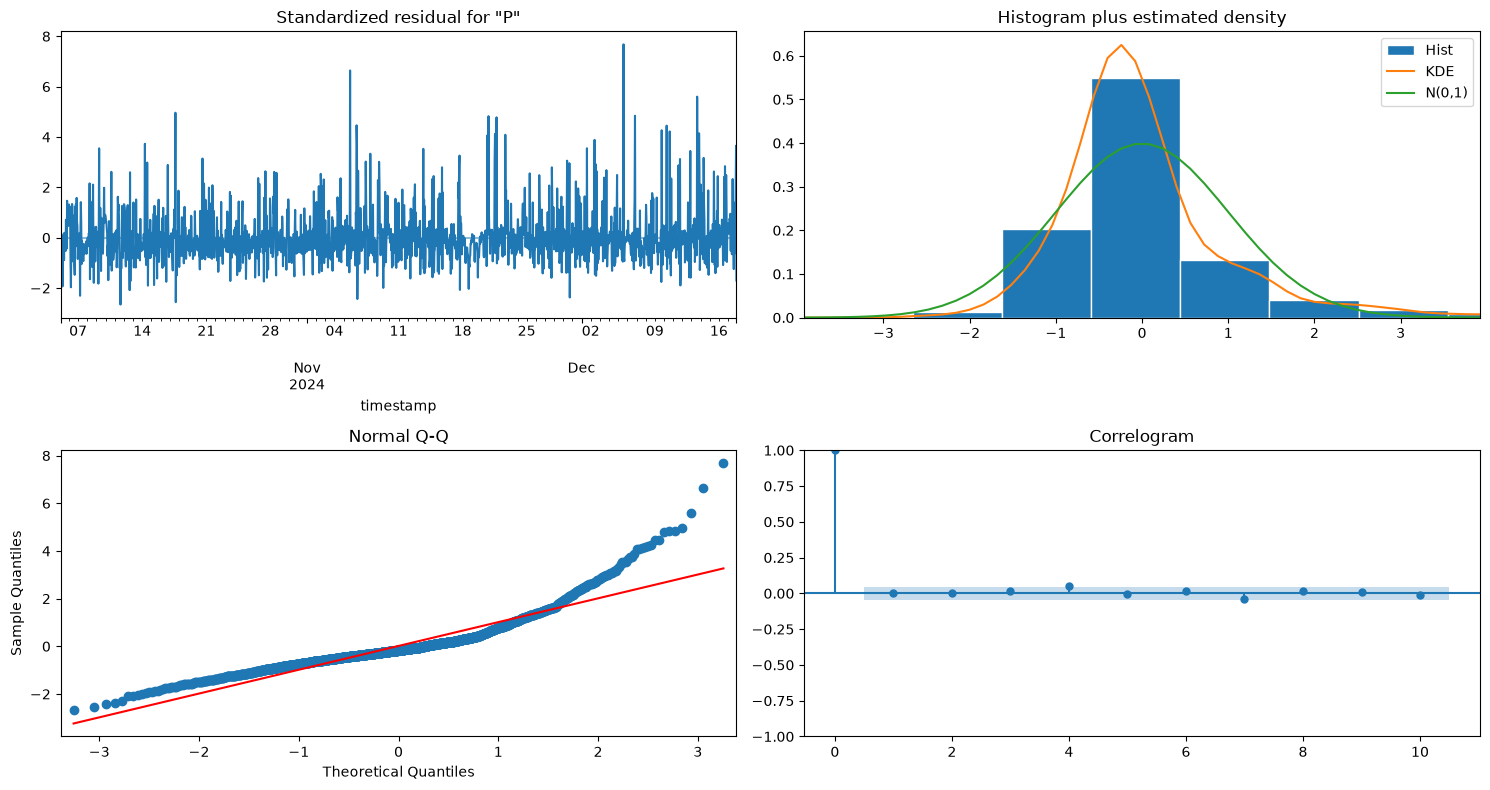

In [12]:
sarima_best.plot_diagnostics(figsize=(15, 8))
plt.tight_layout(); plt.show()

de sprong aan het einde van de qq pot is te verklaren doordat je in eind december uitkomt waar de data zich anders gedraagde

,MAE,RMSE
pred_arima,354.7,502.8
pred_sarima,378.0,537.1
pred_mean,413.5,553.9
pred_last,400.2,649.3
pred_seasonal,471.1,703.1


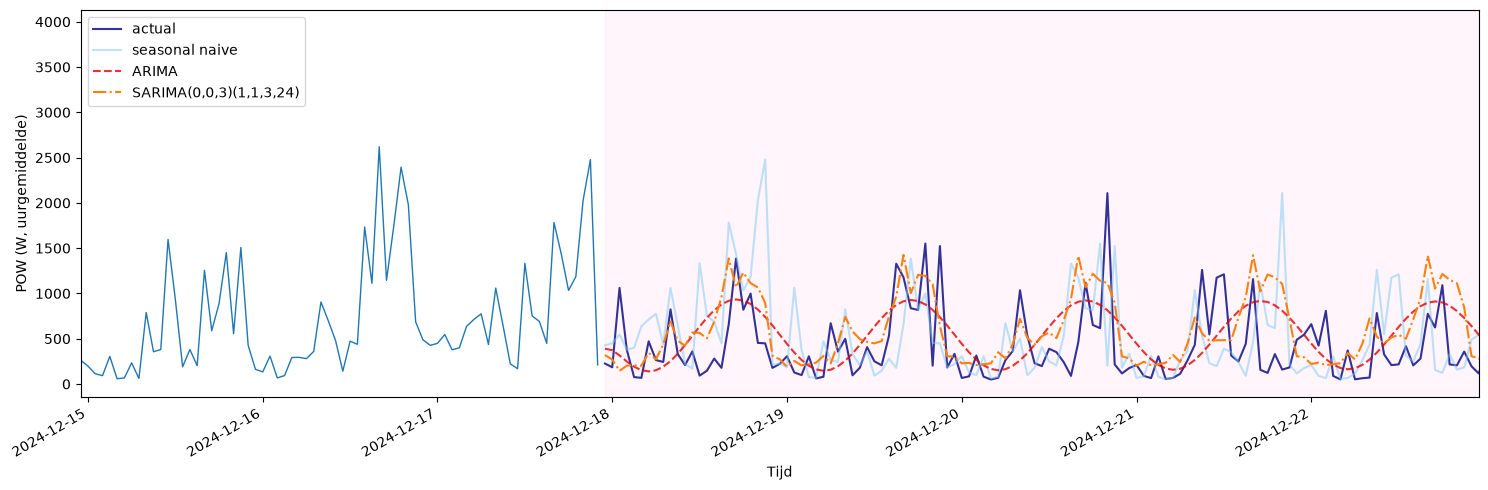

In [13]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(train, linewidth=1)
ax.plot(test_df['actual'],        color='#000080', linestyle='-',  label='actual',         alpha=0.8)
ax.plot(test_df['pred_seasonal'], color='#7Bc8F6', linestyle='-',  label='seasonal naive', alpha=0.5)
ax.plot(test_df['pred_arima'],    color='#E50000', linestyle='--', label='ARIMA',          alpha=0.8)
ax.plot(test_df['pred_sarima'],   color='#FF7F0E', linestyle='-.', label=f'SARIMA({p},0,{q})({P},1,{Q},{m})')
ax.axvspan(test.index[0], test.index[-1],            color='#FFCDEA',                      alpha=0.2)
ax.set_xlim(test.index[0] - pd.Timedelta(days=3), test.index[0] + pd.Timedelta(days=5))
ax.legend(loc=2); ax.set_xlabel('Tijd'); ax.set_ylabel('POW (W, uurgemiddelde)')
fig.autofmt_xdate(); plt.tight_layout()

scores = {naam: {'MAE': mean_absolute_error(test_df['actual'], test_df[naam]),
                 'RMSE': root_mean_squared_error(test_df['actual'], test_df[naam])}
          for naam in ['pred_mean', 'pred_last', 'pred_seasonal', 'pred_arima', 'pred_sarima']}
pd.DataFrame(scores).T.round(1).sort_values('RMSE')

### Resultaten opslaan
---
- Zelfde format als de andere modellen, opgeslagen in `models/results/`
- Eén forecast van 2 weken (336 uur) vanaf het einde van train, dus geen rolling validation
- MAE dag 1/2/3 = eerste 24, 25-48 en 49-72 uur van die forecast
- Let op: andere data (Q4 2024, lineair geïmputeerd), testperiode en resolutie (uur) dan de andere modellen

In [14]:
modelnamen = {"pred_arima": f"ARIMA{arima_best.model.order}", "pred_sarima": "SARIMA", "pred_mean": "Gemiddelde train",
               "pred_last": "Laatste waarde", "pred_seasonal": "Seasonal naive (24u)"}

rijen = {}
for kolom, naam in modelnamen.items():
    fout = (test_df[kolom] - test_df["actual"]).to_numpy()
    res = {"MAE": np.abs(fout).mean(), "RMSE": np.sqrt((fout ** 2).mean())}
    for dag in range(3):
        res[f"MAE dag {dag + 1}"] = np.abs(fout[dag * 24:(dag + 1) * 24]).mean()
    rijen[naam] = res

resultaten = pd.DataFrame(rijen).T
resultaten.loc[modelnamen["pred_arima"], "trainingstijd (s)"] = runtimes["training ARIMA"]
resultaten.loc[modelnamen["pred_arima"], "voorspeltijd (s)"] = runtimes["voorspellen ARIMA"]
resultaten.loc["SARIMA", "trainingstijd (s)"] = runtimes["training SARIMA"]
resultaten.loc["SARIMA", "voorspeltijd (s)"] = runtimes["voorspellen SARIMA"]
resultaten = resultaten.round(1)

#Model opslaan en bestandsgrootte meten
MODEL_DIR = ROOT / "models" / "saved_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def grootte_mb(pad):
    pad = Path(pad)
    if pad.is_dir():
        return sum(f.stat().st_size for f in pad.rglob("*") if f.is_file()) / 1e6
    return pad.stat().st_size / 1e6

import copy

#remove_data=True: alleen het model opslaan, niet de trainingsdata
for naam, fit in [(modelnamen["pred_arima"], arima_best), ("SARIMA", sarima_best)]:
    pad = MODEL_DIR / f"baseline_{naam.split('(')[0].lower()}_huis_cons.pkl"
    copy.deepcopy(fit).save(pad, remove_data=True)
    resultaten.loc[naam, "modelgrootte (MB)"] = grootte_mb(pad)
resultaten["modelgrootte (MB)"] = resultaten["modelgrootte (MB)"].round(3)

KOLOMMEN = ["notebook", "locatie", "target", "resolutie", "testperiode", "MAE", "RMSE", "MAE dag 1", "MAE dag 2",
            "MAE dag 3", "rolling MAE", "rolling RMSE", "trainingstijd (s)", "voorspeltijd (s)",
            "modelgrootte (MB)"]
resultaten["notebook"] = "Baseline_SARIMA_vMS"
resultaten["locatie"] = "huis"
resultaten["target"] = "consumption"
resultaten["resolutie"] = "1 uur"
resultaten["testperiode"] = f"{test.index.min():%Y-%m-%d} t/m {test.index.max():%Y-%m-%d}"
resultaten = resultaten.reindex(columns=KOLOMMEN)
resultaten.to_csv(RESULTS_DIR / "baseline_huis_cons.csv")
resultaten

,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s),modelgrootte (MB)
"ARIMA(3, 0, 3)",Baseline_SARIMA_vMS,huis,consumption,1 uur,2024-12-17 t/m 2024-12-31,354.7,502.8,304.5,303.3,352.3,NaN,NaN,1.0,0.0,1.150
SARIMA,Baseline_SARIMA_vMS,huis,consumption,1 uur,2024-12-17 t/m 2024-12-31,378.0,537.1,306.0,276.4,317.2,NaN,NaN,107.9,0.1,455.951
Gemiddelde train,Baseline_SARIMA_vMS,huis,consumption,1 uur,2024-12-17 t/m 2024-12-31,413.5,553.9,317.7,382.4,359.0,NaN,NaN,NaN,NaN,NaN
Laatste waarde,Baseline_SARIMA_vMS,huis,consumption,1 uur,2024-12-17 t/m 2024-12-31,400.2,649.3,265.9,345.3,282.7,NaN,NaN,NaN,NaN,NaN
Seasonal naive (24u),Baseline_SARIMA_vMS,huis,consumption,1 uur,2024-12-17 t/m 2024-12-31,471.1,703.1,471.2,320.5,403.9,NaN,NaN,NaN,NaN,NaN
